# 01 - Data loading, leakage audit, split and EDA

## How to reproduce

From the repository root (Python 3.11, uv installed):

```sh
uv sync --locked
uv run jupyter nbconvert --to notebook --execute --inplace notebooks/01_data_and_eda.ipynb
```

Needs `datasets/raw/Weapon Detection.zip`. The first run extracts the ZIP and computes features (a few minutes on a laptop CPU); later runs use the cache.
The measured runtime is printed in the last cell.

**Seed.** Everything random uses seed 42, so every run gives the same split and the same models.

In [1]:
# Fixed seed for everything random in this notebook (the modules use SEED = 42 too).
import random
import time

import numpy as np
import pandas as pd
from IPython.display import Image, display

from weapon_detection.ml.common import OUTPUT_DIR, SEED

random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.width", 200)
notebook_start = time.perf_counter()
print("SEED =", SEED)

SEED = 42


**Step 1 - Load, label and audit the data.** `prepare_data.main()` checks the ZIP, extracts it safely, reads every YOLO label, marks an image as *firearm* if it has a Gun or Pistol box, finds duplicates / near duplicates / video-frame families, and builds the group-aware split. We split BEFORE any model is trained so the test set stays unseen.

In [2]:
from weapon_detection.ml import prepare_data

prepare_data.main()

ZIP CRC check: OK
Class names from data.yaml:
id  name            firearm?
0   Card            False   
1   Currency Notes  False   
2   Gun             True    
3   Knife           False   
4   Mobile          False   
5   Pistol          True    



Per original split:
split  images  label_files  images_without_label_file  label_files_without_image  empty_label_files  malformed_label_lines  corrupt_images
train  6598    6598         0                          0                          14                 0                      0             
valid  1884    1884         0                          0                          8                  0                      0             
test   943     943          0                          0                          5                  0                      0             

Objects per class per original split:
split  Card  Currency Notes  Gun   Knife  Mobile  Pistol
train  14    133             4539  597    68      3033  
valid  2     41              1260  172    12      861   
test   4     18              656   91     8       417   

Images used: 9425  positives: 8304  negatives: 1121



Filename families used (20 families, 778 images):
family               images
billete              179   
kravmagatraining     159   
defensetechniques    115   
defenseknifeattack   88    
rusoclases           23    
abbframe             22    
mbbframe             21    
lbbframe             19    
hbbframe             17    
mbmframe             17    
lbmframe             15    
hbsframe             14    
lbsframe             14    
krav                 13    
abmframe             12    
absframe             12    
hbmframe             12    
mbsframe             11    
realityknifeattacks  9     
defenseandsurvive    6     



Negative groups: 315 groups, 1029 images
group   images  source             
g06476  181     billete            
g00237  159     kravmagatraining   
g00113  115     defensetechniques  
g00409  49      mbbframe           
g00352  48      lbbframe           
g00013  46      abbframe           
g00208  29      hbbframe           
g00422  23      rusoclases         
g00215  14      hbsframe           
g00227  13      krav               
g00417  9       realityknifeattacks
g00047  6       defenseandsurvive  
g01384  5       w19245_monedero    
g01411  4       w19376_smartphone  
g01280  4       w19215_knife       
g01262  3       w19181_knife       
g01150  3       w19013_knife       
g01155  3       w19018_knife       
g06976  3       w19329_sharpenknife
g06992  2       w19469_tarjeta     

Negative group size -> number of groups: {1: 280, 2: 16, 3: 4, 4: 2, 5: 1, 6: 1, 9: 1, 13: 1, 14: 1, 23: 1, 29: 1, 46: 1, 48: 1, 49: 1, 115: 1, 159: 1, 181: 1} 



10 largest groups after merging:
group   images  positives  families                  
g06476  181     0          billete                   
g00237  159     0          kravmagatraining          
g00113  115     0          defensetechniques         
g00051  88      2          defenseknifeattack        
g00409  49      0          mbbframe,mbmframe,mbsframe
g00352  48      0          lbbframe,lbmframe,lbsframe
g00013  46      0          abbframe,abmframe,absframe
g00208  29      0          hbbframe,hbmframe         
g00422  23      0          rusoclases                
g00215  14      0          hbsframe                  

Split v1 positive share per split:
  train: 89.5% positives, 781 negatives
  val: 83.9% positives, 159 negatives
  test: 82.1% positives, 181 negatives

Leakage audit:
check                                          value
images_used                                    9425 
positives                                      8304 
negatives                                    

**Step 2 - Look at the manifest.** One row per image: path, split, group, label. Models never see the path, group or split as inputs.

In [3]:
manifest = pd.read_csv(OUTPUT_DIR / 'manifest.csv')
display(manifest.head())
pd.crosstab(manifest['split'], manifest['firearm_present'], margins=True)

,image_path,original_split,split_v1,split_v2,split,group,family,firearm_present,classes,box_areas,n_objects,width,height
0,datasets/raw/weapon_detection_extracted/train/...,train,train,train,train,g00013,abbframe,0,Knife,0.004494,1,1920,1090
1,datasets/raw/weapon_detection_extracted/train/...,train,train,train,train,g00013,abbframe,0,Knife,0.004418,1,1920,1090
2,datasets/raw/weapon_detection_extracted/train/...,train,train,train,train,g00013,abbframe,0,Knife,0.004026,1,1920,1090
3,datasets/raw/weapon_detection_extracted/train/...,train,train,train,train,g00013,abbframe,0,Knife,0.004537,1,1920,1090
4,datasets/raw/weapon_detection_extracted/train/...,train,train,train,train,g00013,abbframe,0,Knife,0.004647,1,1920,1090


firearm_present,0,1,All
split,,,
test,90,831,921
train,941,6642,7583
val,90,831,921
All,1121,8304,9425


**Step 3 - Pre-processing: features.** Each image is resized to 128x128; we compute 10 interpretable numbers (brightness, edges, colour, ...) and a HOG vector. These are per-image calculations, so nothing is *fitted* here (scaling is fitted later on the training split only).

In [4]:
from weapon_detection.ml import features

features.main()
handcrafted, hog, names = features.load_features(manifest)
print('handcrafted', handcrafted.shape, 'hog', hog.shape)
print(names)

Cache is up to date: /home/sultan/Desktop/repos/weapon-detection/outputs/ml/features.npz (use --force to recompute)


handcrafted (9425, 10) hog (9425, 1764)
['mean_brightness', 'contrast_std', 'edge_density', 'mean_blue', 'mean_green', 'mean_red', 'mean_saturation', 'laplacian_sharpness', 'dark_fraction', 'histogram_entropy']


**Step 4 - Exploratory data analysis.** Figures use the TRAINING split only (except the class counts), so we do not peek at the test set. The notes are facts; the takeaways are written by me in the report.

# EDA notes

All numbers are computed by `weapon_detection/ml/eda.py`. These are factual notes only; the takeaways are written by the student.

- class_balance_per_split.png: firearm images are 87.6% of train, 90.2% of val, 90.2% of test; always predicting 'firearm' gives 90.2% accuracy on test.
- object_class_counts.png: firearm classes account for 10766 of 11926 objects (90.3%); the largest non-firearm class is Knife.
- firearm_box_area_hist.png: the median firearm box covers 11.2% of the image and 31.0% of 8605 train boxes cover under 5%.
- image_size_distribution.png: 2156 distinct sizes in train; the most common is 1280x720 (9.8% of train images); all images are resized to 128x128 before feature extraction.
- feature_distributions.png: mean_brightness median 114 (firearm) vs 115 (no firearm); edge_density median 0.114 (firearm) vs 0.1 (no firearm); mean_saturation median 57.2 (firearm) vs 42.6 (no firearm); laplacian_sharpness median 1.5e+03 (firearm) vs 1.42e+03 (no firearm).



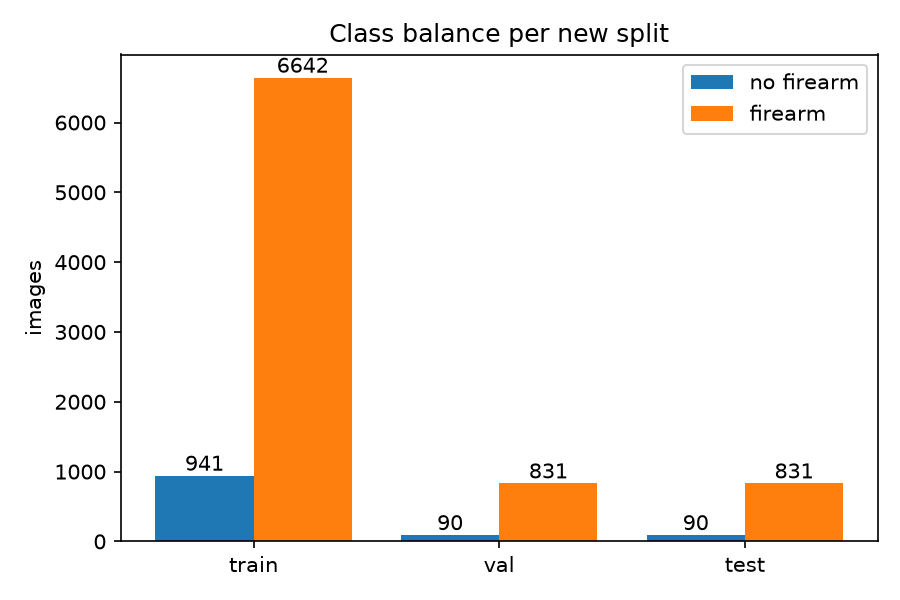

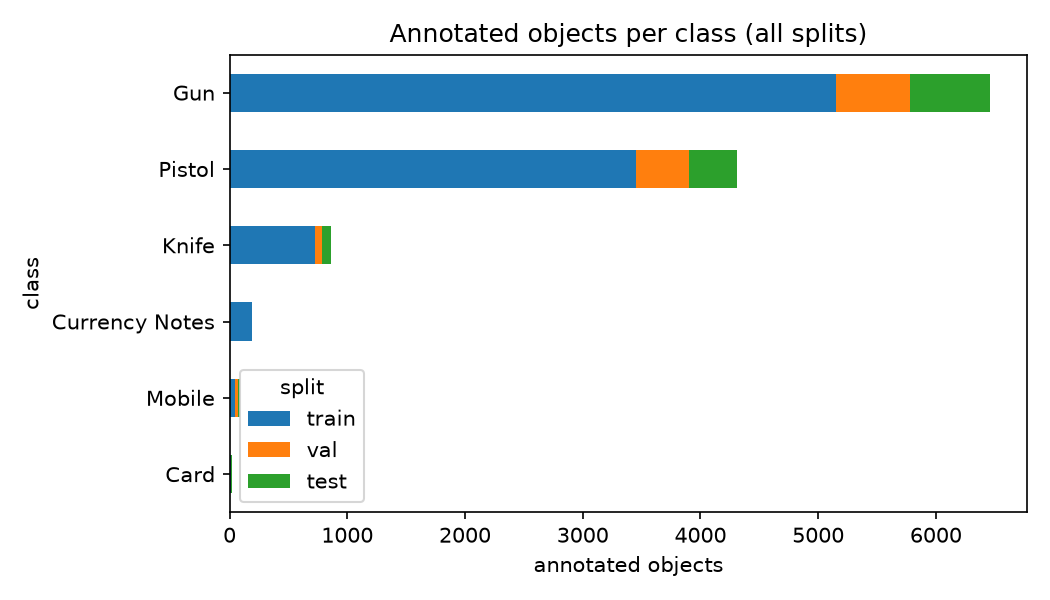

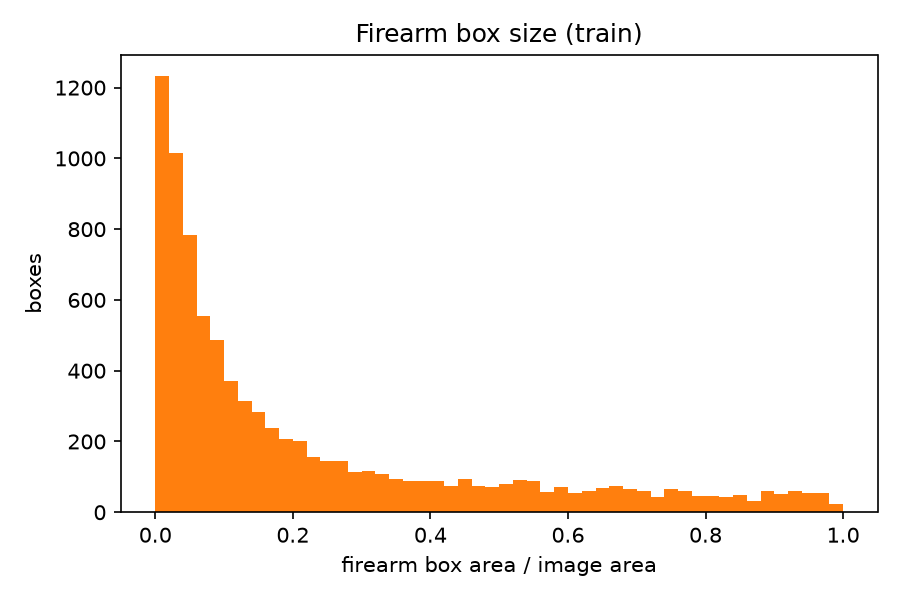

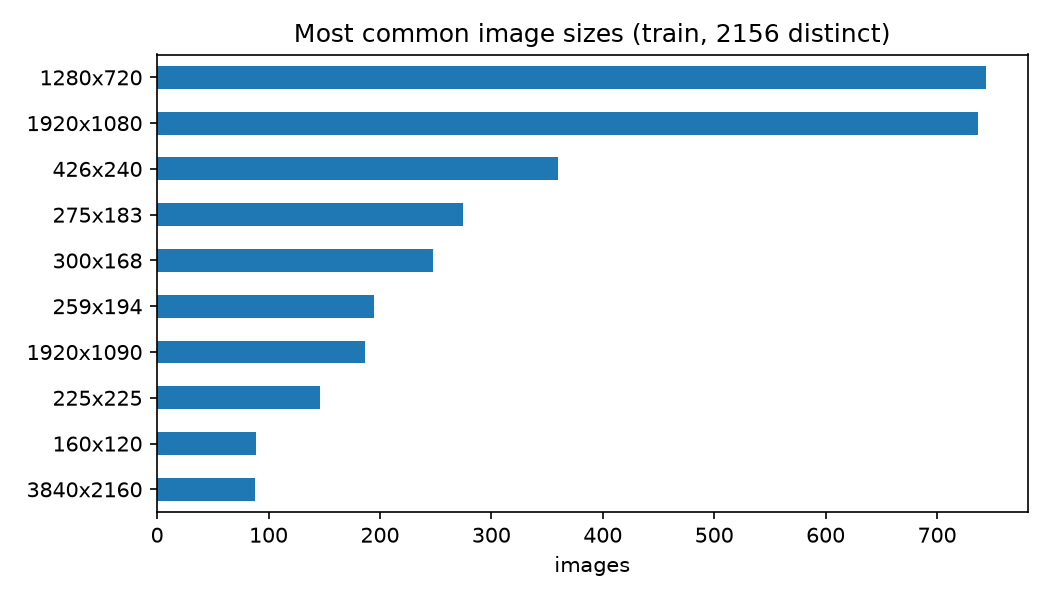

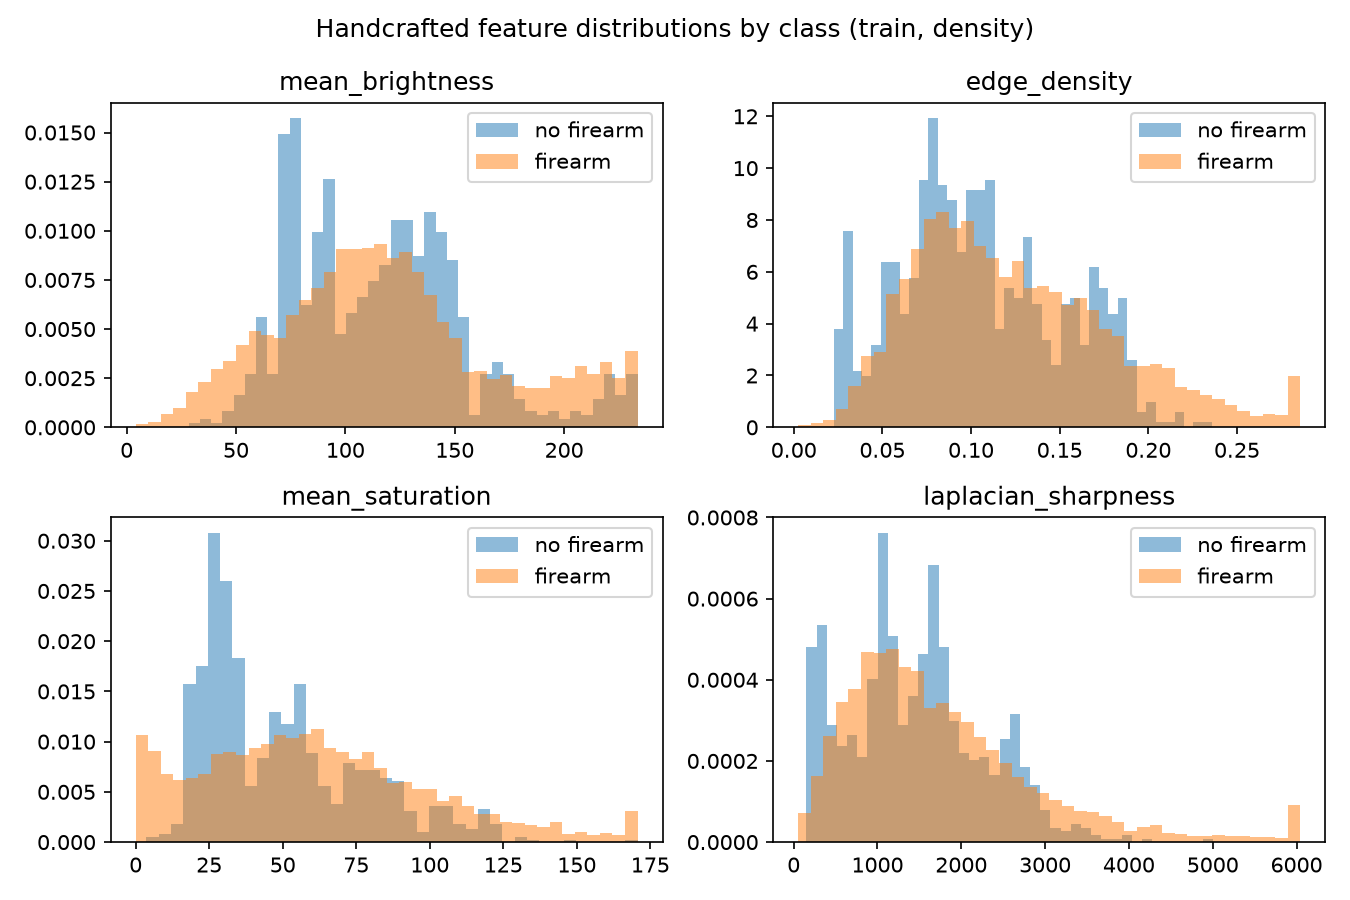

In [5]:
from weapon_detection.ml import eda

eda.main()
for name in ['class_balance_per_split', 'object_class_counts', 'firearm_box_area_hist',
             'image_size_distribution', 'feature_distributions']:
    display(Image(filename=str(OUTPUT_DIR / 'figures' / f'{name}.png'), width=650))

**Step 5 - Leakage audit numbers.** Where do the negatives of each split come from? Split v1 vs split v2 (v2 was introduced after preliminary v1 results; see report).

In [6]:
import json

audit = json.loads((OUTPUT_DIR / 'audit.json').read_text())
for version in ['negative_sources_v1', 'negative_sources_v2']:
    print(version)
    display(pd.DataFrame(audit['split_v2'][version]).T)

negative_sources_v1


,images,positives,negatives,distinct_negative_groups,largest_negative_group_share
train,7425.0,6644.0,781.0,317.0,0.1472
val,989.0,830.0,159.0,1.0,1.0000
test,1011.0,830.0,181.0,1.0,1.0000


negative_sources_v2


,images,positives,negatives,distinct_negative_groups,largest_negative_group_share
train,7583.0,6642.0,941.0,151.0,0.1923
val,921.0,831.0,90.0,87.0,0.0222
test,921.0,831.0,90.0,81.0,0.0444


**Runtime.**

In [7]:
# Measured runtime of this notebook on the machine that executed it.
print(f"Notebook runtime: {time.perf_counter() - notebook_start:.0f} seconds")

Notebook runtime: 46 seconds
